# Le réseau ferré français vu comme un graphe

*Cours* Metabolic networks : graph analysis *(C. Frainay, F. Jourdan, INRAE Toxalim)*. Rapport réalisé avec Cytoscape 3.10.5, piloté depuis Python (py4cytoscape), et NetworkX.

## Introduction

Le cours applique la théorie des graphes aux réseaux métaboliques. Nous appliquons les mêmes outils à un autre réseau réel, le réseau ferré national : les villes sont les nœuds, les voies ferrées qui les relient sont les arêtes. Comme le rappelle le cours, il faut d'abord bien définir ce que sont les nœuds et les arêtes, puis préparer le graphe, avant de calculer quoi que ce soit.

### Sources des données

Toutes les données sont ouvertes et téléchargeables gratuitement.

| Fichier | Producteur | Ce qu'on en tire |
|---|---|---|
| [Liste des gares](https://ressources.data.sncf.com/explore/dataset/liste-des-gares/) | SNCF Réseau | les gares voyageurs, leur commune, leur ligne et leur position sur la ligne (point kilométrique) |
| [Formes des voies du réseau ferré national](https://ressources.data.sncf.com/explore/dataset/fichier-de-formes-des-voies-du-reseau-ferre-national/) | SNCF Réseau | le tracé des voies : où les lignes se croisent |
| [Lignes par statut](https://ressources.data.sncf.com/explore/dataset/lignes-par-statut/) | SNCF Réseau | le tracé de chaque ligne : longueur réelle des liaisons, part sur ligne à grande vitesse |
| [Vitesse maximale nominale sur ligne](https://ressources.data.sncf.com/explore/dataset/vitesse-maximale-nominale-sur-ligne/) | SNCF Réseau | la vitesse permise, pour retrouver l'itinéraire de chaque train |
| [Horaires SNCF (format GTFS)](https://ressources.data.sncf.com/explore/dataset/horaires-sncf/) | SNCF Voyageurs | les trains d'un mardi ordinaire (1er décembre 2026) : TER, TGV, Intercités |
| [Fréquentation en gares](https://ressources.data.sncf.com/explore/dataset/frequentation-gares/) | SNCF Voyageurs | le nombre de voyageurs de chaque gare en 2025 |
| [Découpage administratif](https://github.com/etalab/decoupage-administratif) | Etalab | le code INSEE, la population, le département et la région de chaque commune |

### Un script pour tout agréger

Ces fichiers ne forment pas un graphe tels quels. Nous avons écrit un script, `preprocessing_datasets.py`, qui les agrège en quatre étapes :

1. il relie deux gares voisines sur une même ligne, puis raccorde les lignes entre elles là où leurs tracés se croisent ;
2. il fait circuler chaque train des horaires sur l'itinéraire le plus rapide, pour compter les trains de chaque liaison ;
3. il regroupe toutes les gares d'une même commune en un seul nœud, la ville (Paris compte 31 gares, Lyon 6), et mesure chaque liaison le long de la voie ;
4. il vérifie le résultat (pas de doublon, pas de boucle, pas de liaison vers une ville inconnue) et écrit deux tables, `villes.csv` et `liaisons.csv`, ainsi que le fichier `reseau_villes.cyjs`, qui s'ouvre directement dans Cytoscape.

### Les variables

**Nœuds : `villes.csv`, 2 597 villes.** Une ligne par commune qui possède au moins une gare voyageurs.

| Variable | Signification |
|---|---|
| `id` | code INSEE de la commune (identifiant du nœud) |
| `nom`, `departement`, `region` | nom de la commune et codes de son département et de sa région |
| `lon`, `lat` | coordonnées géographiques (moyenne des gares de la ville) |
| `nb_gares` | nombre de gares voyageurs de la ville |
| `voyageurs_2025` | voyageurs de ses gares en 2025 |
| `population` | nombre d'habitants de la commune |
| `nb_trains_jour` | trains qui s'arrêtent dans la ville un mardi ordinaire |
| `statut_desserte` | desservie, non desservie (gare sans train), ou inconnue en Île-de-France (trains de banlieue absents des horaires) |

**Arêtes : `liaisons.csv`, 3 182 liaisons.** Une ligne par tronçon de voie entre deux villes voisines, sans gare intermédiaire.

| Variable | Signification |
|---|---|
| `source`, `target` | codes INSEE des deux villes reliées (le graphe n'est pas orienté) |
| `code_ligne` | numéro de la ou des lignes empruntées |
| `type_ligne`, `part_lgv` | LGV (ligne à grande vitesse) si plus de la moitié du tracé est à grande vitesse, sinon classique ; part du tracé à grande vitesse |
| `nb_trains_jour` | trains qui empruntent la liaison un mardi ordinaire, deux sens confondus |
| `longueur_km` | longueur le long de la voie : **c'est le poids des arêtes** |
| `vol_oiseau_km`, `detour` | distance en ligne droite, et rapport longueur / ligne droite |

### Méthode

Chaque question suit le même schéma : la question, le code, le graphique, puis une légende qui répond. Le code charge le fichier `.cyjs` dans Cytoscape, y ajoute les résultats calculés comme nouvelles colonnes, règle le style (couleur, taille, épaisseur selon une colonne) et exporte la vue. Les villes sont placées à leurs coordonnées géographiques : pour un réseau de transport, la position a un sens, contrairement à une carte métabolique (*« la carte n'est pas le territoire »*). Cytoscape calcule lui-même ce qu'il sait calculer (degré, regroupement, mesures sans poids avec *Analyze Network*) ; NetworkX calcule ce qui demande des distances en km.

In [1]:
from pathlib import Path
import random
import time

import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import py4cytoscape as p4c
from matplotlib.lines import Line2D

DONNEES, FIGURES = Path("data/genere"), Path("figures/rapport")
FIGURES.mkdir(parents=True, exist_ok=True)
villes = pd.read_csv(DONNEES / "villes.csv", dtype={"id": str, "departement": str, "region": str}).set_index("id")
liaisons = pd.read_csv(DONNEES / "liaisons.csv", dtype={"source": str, "target": str, "code_ligne": str})
liaisons["cle"] = liaisons.source + "~" + liaisons.target  # même clé que dans le fichier Cytoscape

# Graphe NetworkX : G complet, P = plus grande composante connexe (le « réseau principal »)
G = nx.from_pandas_edgelist(liaisons, "source", "target", edge_attr=True)
G.add_nodes_from(villes.index)
P = G.subgraph(max(nx.connected_components(G), key=len)).copy()
KM = "longueur_km"  # poids des arêtes
print(f"{G.number_of_nodes()} villes, {G.number_of_edges()} liaisons, {nx.number_connected_components(G)} composantes ; "
      f"réseau principal : {P.number_of_nodes()} villes")

# Cytoscape : session vide, puis import du réseau (File → Import → Network from File)
p4c.cytoscape_ping()
p4c.close_session(False)
BASE = p4c.import_network_from_file(str((DONNEES / "reseau_villes.cyjs").resolve()))["networks"][0]

BLEU, ORANGE, GRIS, CLAIR, FONCE = "#2a78d6", "#eb6834", "#c3c2b7", "#cde2fb", "#0d366b"


def colonne(valeurs, nom, table="node", reseau=None):
    """Ajoute une colonne calculée en Python à la table des nœuds (ou des arêtes) de Cytoscape, grâce à la clé `cle`."""
    p4c.load_table_data(valeurs.rename(nom).rename_axis("cle").reset_index(), data_key_column="cle",
                        table=table, table_key_column="cle", network=reseau or BASE)


def etiquettes(ids):
    """Colonne `etiquette` : nom des villes à afficher, vide pour les autres."""
    noms = pd.Series("", index=villes.index)
    noms[list(ids)] = villes.nom[list(ids)]
    colonne(noms, "etiquette")


def style(nom, reseau=None, noeud=6, arete=1, etiquette="etiquette", police=40):
    """Nouveau style (panneau Style) : petits nœuds bleu clair, liaisons grises, étiquettes lues dans une colonne."""
    reseau = reseau or BASE
    p4c.set_current_network(reseau)
    if nom in p4c.get_visual_style_names():
        p4c.delete_visual_style(nom)
    p4c.create_visual_style(nom, defaults={"NODE_SIZE": noeud, "NODE_FILL_COLOR": CLAIR, "NODE_BORDER_WIDTH": 0,
                                           "NODE_LABEL_FONT_SIZE": police, "NODE_LABEL_POSITION": "S,N,c,0.00,0.00", "EDGE_WIDTH": arete,
                                           "EDGE_STROKE_UNSELECTED_PAINT": GRIS})
    if etiquette:
        p4c.set_node_label_mapping(etiquette, style_name=nom)
    p4c.set_visual_style(nom, network=reseau)


def nouveau_reseau(noeuds, aretes, titre, x, y):
    """Crée un réseau Cytoscape à partir de deux tables ; les nœuds sont placés aux positions x, y."""
    reseau = p4c.create_network_from_data_frames(noeuds, aretes, title=titre)
    table = p4c.get_table_columns("node", ["id"], network=reseau)
    suid = pd.Series(table.index, index=table["id"].astype(str))
    for valeurs, propriete in [(x, "NODE_X_LOCATION"), (y, "NODE_Y_LOCATION")]:
        p4c.set_node_property_bypass([int(s) for s in suid[valeurs.index.astype(str)]], [float(v) for v in valeurs],
                                     propriete, network=reseau)
    return reseau


def trait(couleur, epaisseur, texte):
    return Line2D([], [], color=couleur, lw=epaisseur, label=texte)


def point(couleur, taille, texte, bord="none"):
    return Line2D([], [], color="none", marker="o", markerfacecolor=couleur, markeredgecolor=bord,
                  markersize=taille, label=texte)


def figure(nom, titre, reseau=None, legende=(), graphique=None):
    """Exporte la vue Cytoscape en PNG et l'affiche, avec à droite un graphique facultatif."""
    reseau = reseau or BASE
    p4c.clear_selection(network=reseau)
    p4c.fit_content(network=reseau)
    time.sleep(1.5)  # laisser Cytoscape dessiner la vue
    p4c.fit_content(network=reseau)
    png = (FIGURES / f"{nom}_cytoscape.png").resolve()
    p4c.export_image(str(png), type="PNG", zoom=200, network=reseau, overwrite_file=True)
    fig, axes = plt.subplots(1, 2 if graphique else 1, figsize=(15 if graphique else 8, 7.5), squeeze=False,
                             gridspec_kw={"width_ratios": [1.1, 1]} if graphique else None)
    ax = axes[0, 0]
    ax.imshow(mpimg.imread(png))
    ax.set_axis_off()
    if legende:
        ax.legend(handles=legende, loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=2, frameon=False, fontsize=9)
    if graphique:
        graphique(axes[0, 1])
        axes[0, 1].spines[["top", "right"]].set_visible(False)
    fig.suptitle(titre, fontsize=13)
    plt.tight_layout()
    plt.savefig(FIGURES / f"{nom}.png", bbox_inches="tight", dpi=110)
    plt.show()

2597 villes, 3182 liaisons, 3 composantes ; réseau principal : 2595 villes
You are connected to Cytoscape!


**Q1. Où sont les lignes à grande vitesse ?**

82 liaisons LGV sur 3182, soit 4334 km à grande vitesse (10% des km du réseau)


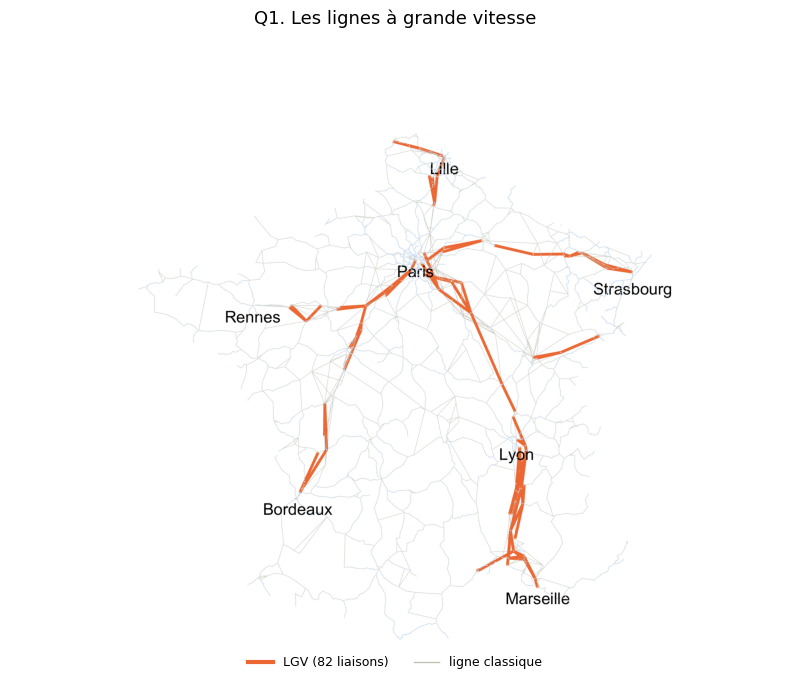

In [2]:
# Style → Edge → Stroke Color et Width : colonne type_ligne, correspondance discrète (Discrete Mapping)
etiquettes(["75056", "69123", "13055", "33063", "59350", "67482", "35238"])
style("Q1", noeud=3)
p4c.set_edge_color_mapping("type_ligne", ["LGV", "classique"], [ORANGE, GRIS], mapping_type="d", style_name="Q1")
p4c.set_edge_line_width_mapping("type_ligne", ["LGV", "classique"], [7, 1], mapping_type="d", style_name="Q1")

lgv = liaisons[liaisons.type_ligne == "LGV"]
km_lgv = (liaisons.longueur_km * liaisons.part_lgv.fillna(0)).sum()
print(f"{len(lgv)} liaisons LGV sur {len(liaisons)}, soit {km_lgv:.0f} km à grande vitesse "
      f"({km_lgv / liaisons.longueur_km.sum():.0%} des km du réseau)")
figure("Q1_lgv", "Q1. Les lignes à grande vitesse",
       legende=[trait(ORANGE, 3, f"LGV ({len(lgv)} liaisons)"), trait(GRIS, 1, "ligne classique")])

*Figure 1.* Réseau des villes dans Cytoscape, chaque ville placée à ses coordonnées. Les liaisons sont colorées selon leur attribut `type_ligne` : orange pour les lignes à grande vitesse, gris pour les lignes classiques.

**Réponse :** les lignes à grande vitesse forment une étoile centrée sur Paris, à quatre branches : vers Lyon et Marseille au sud-est, vers Bordeaux et Rennes à l'ouest, vers Lille au nord, vers Strasbourg à l'est. Seules la ligne Rhin-Rhône (Dijon-Mulhouse) et le contournement de Nîmes et Montpellier ne partent pas de Paris. Elles ne représentent qu'une faible part des liaisons du graphe, car elles relient de grandes villes très éloignées sans arrêt intermédiaire : un même attribut d'arête, ici le type de ligne, suffit à faire apparaître la structure en étoile du réseau.

**Q2. Où circulent les trains ?**

Liaisons sans aucun train ce jour-là : 20%


,de,vers,nb_trains_jour,longueur_km
688,Eckwersheim,Mundolsheim,321,3.692
1621,Mundolsheim,Strasbourg,321,7.770
90,Montgeron,Yerres,301,1.674
148,Combs-la-Ville,Boussy-Saint-Antoine,301,2.149
174,Brunoy,Yerres,301,2.303


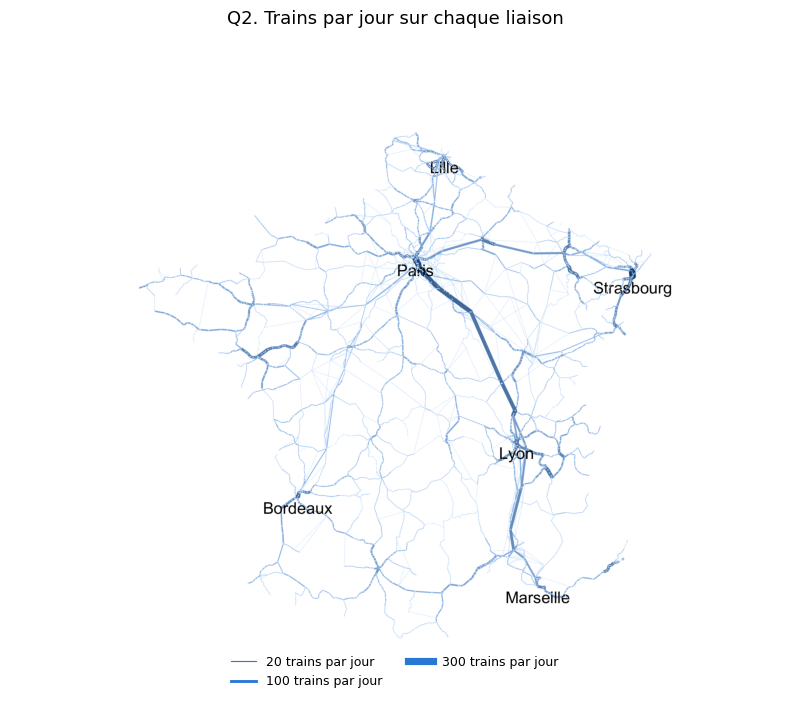

In [3]:
# Style → Edge → Width et Stroke Color : colonne nb_trains_jour, correspondance continue (Continuous Mapping)
maxi = float(liaisons.nb_trains_jour.max())
etiquettes(["75056", "69123", "59350", "67482", "13055", "33063"])
style("Q2", noeud=3)
p4c.set_edge_line_width_mapping("nb_trains_jour", [0, maxi], [0.5, 16], style_name="Q2")
p4c.set_edge_color_mapping("nb_trains_jour", [0, maxi], ["#9ec5f4", FONCE], style_name="Q2")

print(f"Liaisons sans aucun train ce jour-là : {(liaisons.nb_trains_jour == 0).mean():.0%}")
display(liaisons.nlargest(5, "nb_trains_jour")
        .assign(de=lambda t: villes.nom[t.source].values, vers=lambda t: villes.nom[t.target].values)
        [["de", "vers", "nb_trains_jour", "longueur_km"]])
figure("Q2_trains", "Q2. Trains par jour sur chaque liaison",
       legende=[trait(BLEU, 0.5 + 5 * n / maxi, f"{n} trains par jour") for n in (20, 100, 300)])

*Figure 2.* Le graphe pondéré par le service. L'épaisseur et la teinte de chaque liaison sont proportionnelles au nombre de trains qui l'empruntent un mardi ordinaire, deux sens confondus.

**Réponse :** les trains circulent surtout sur les grands axes qui partent de Paris (vers Lyon et Marseille, Lille, Strasbourg) et autour des grandes métropoles régionales (Lyon, Lille, Strasbourg), où les TER forment de petites étoiles. Une liaison sur cinq n'a aucun train ce jour-là : ce sont surtout des liaisons de banlieue parisienne, dont les trains (Transilien, RER) manquent aux horaires utilisés, et des lignes fermées aux voyageurs. Le même graphe porte donc deux poids différents : la longueur (l'infrastructure) et le nombre de trains (le service).

**Q3. Quelles gares sont les plus connectées, et le réseau a-t-il des carrefours géants ?**

Applying default style...
Applying preferred layout


,nom,Degree,trains_par_jour
id,,,
87723197,Lyon Part Dieu,33,715.0
87212027,Strasbourg,29,726.0
87471003,Rennes,24,383.0
87396002,Le Mans,22,285.0
87286005,Lille Flandres,22,560.0
87581009,Bordeaux Saint-Jean,21,466.0


Gares de degré 1 (une seule gare voisine) : 72 sur 2641


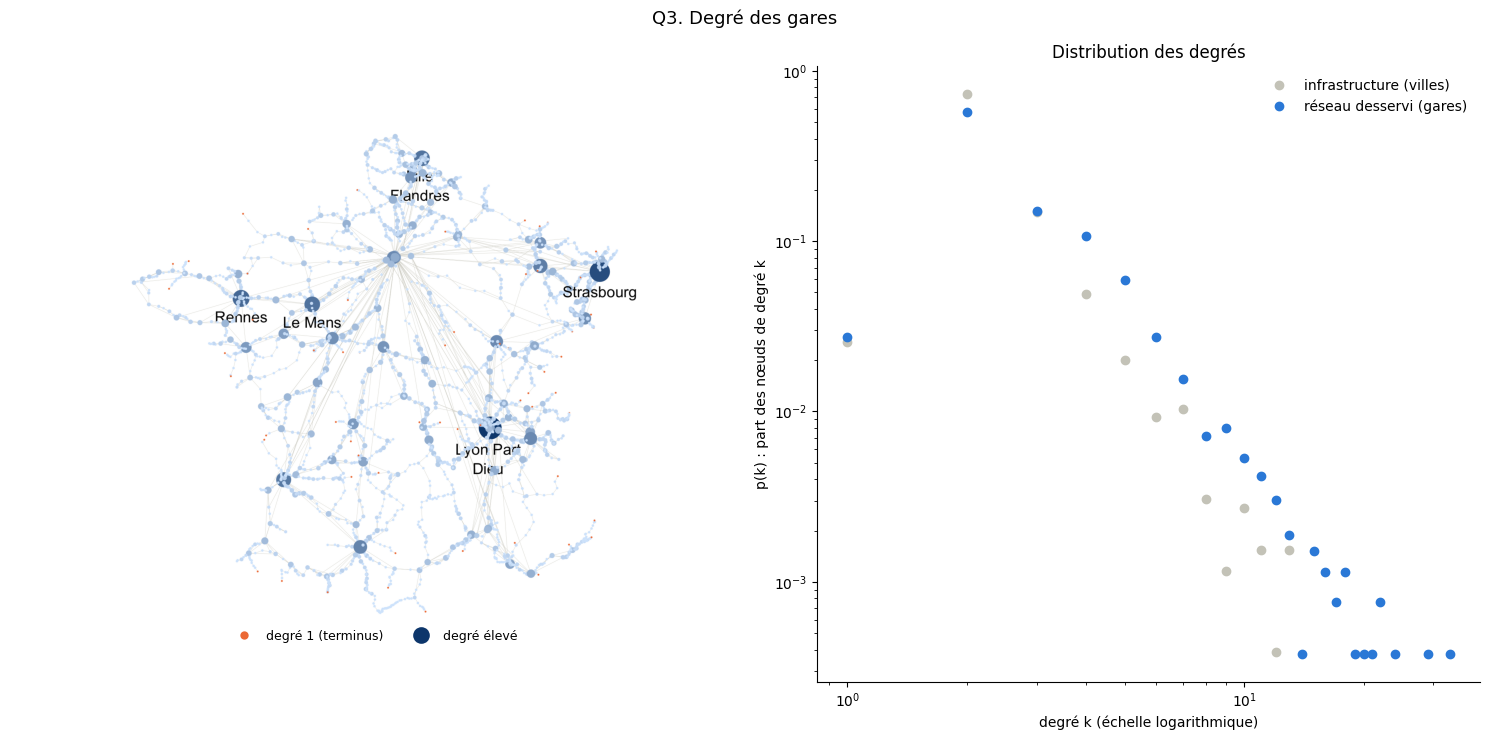

In [4]:
# Réseau « desservi » : une gare par nœud, une arête quand un train relie deux gares sans arrêt intermédiaire
gares = pd.read_csv(DONNEES / "gtfs_fr_nodes.csv", dtype={"id": str})
dessertes = pd.read_csv(DONNEES / "gtfs_fr_edges.csv", dtype={"source": str, "target": str})
gares = gares[gares.id.isin(set(dessertes.source) | set(dessertes.target))]
reseau_d = nouveau_reseau(gares, dessertes, "Réseau desservi", gares.set_index("id").lon * 100, -gares.set_index("id").lat * 145)

# Tools → Analyze Network : Cytoscape calcule le degré de chaque nœud (colonne Degree)
p4c.set_current_network(reseau_d)
p4c.analyze_network()
degre = p4c.get_table_columns("node", ["id", "nom", "Degree"], network=reseau_d).set_index("id")
trains = pd.concat([dessertes.groupby("source").nb_trains.sum(), dessertes.groupby("target").nb_trains.sum()], axis=1).sum(axis=1)
degre["trains_par_jour"] = trains.reindex(degre.index)
display(degre.nlargest(6, "Degree"))
print(f"Gares de degré 1 (une seule gare voisine) : {(degre.Degree == 1).sum()} sur {len(degre)}")

# Degré dans l'infrastructure (réseau des villes), lui aussi par Analyze Network
p4c.set_current_network(BASE)
analyse_base = p4c.analyze_network()
degre_villes = p4c.get_table_columns("node", ["cle", "Degree"], network=BASE).set_index("cle").Degree

etiquette_d = degre.nom.where(degre.Degree >= degre.Degree.nlargest(4).min(), "")
p4c.load_table_data(etiquette_d.rename("etiquette").rename_axis("id").reset_index(), data_key_column="id",
                    table_key_column="id", network=reseau_d)
style("Q3", reseau_d, arete=0.6)
dmax = float(degre.Degree.max())
p4c.set_node_size_mapping("Degree", [1, dmax], [5, 60], style_name="Q3")
p4c.set_node_color_mapping("Degree", [1, 2, dmax], [ORANGE, CLAIR, FONCE], style_name="Q3")


def distribution(ax):
    for valeurs, couleur, nom in [(degre_villes[degre_villes > 0], GRIS, "infrastructure (villes)"),
                                  (degre.Degree, BLEU, "réseau desservi (gares)")]:
        pk = valeurs.value_counts(normalize=True).sort_index()
        ax.loglog(pk.index, pk.values, "o", color=couleur, label=nom)
    ax.set_xlabel("degré k (échelle logarithmique)")
    ax.set_ylabel("p(k) : part des nœuds de degré k")
    ax.set_title("Distribution des degrés")
    ax.legend(frameon=False)


figure("Q3_degre", "Q3. Degré des gares", reseau=reseau_d, graphique=distribution,
       legende=[point(ORANGE, 6, "degré 1 (terminus)"), point(FONCE, 12, "degré élevé")])

*Figure 3.* À gauche, le réseau desservi dans Cytoscape (une gare par nœud, une arête quand un train relie deux gares sans s'arrêter entre elles) ; la taille et la couleur codent le degré calculé par *Analyze Network*, les terminus (degré 1) sont en orange. À droite, la distribution des degrés en échelles logarithmiques.

**Réponse :** la gare la plus connectée est Lyon Part-Dieu, reliée en direct à 33 gares, devant Strasbourg et Rennes ; les gares parisiennes, chacune tête de quelques lignes seulement, en desservent peu. Mais le réseau n'a pas de carrefour géant : presque toutes les villes ont un degré 2 (au milieu d'une ligne) et la distribution chute très vite, sans la longue traîne en loi de puissance des réseaux « sans échelle » vus en cours (réseaux d'interactions de protéines, réseaux métaboliques). La géographie limite le nombre de voies qui peuvent partir d'une gare, alors qu'un métabolite comme l'ATP peut participer à des centaines de réactions.

**Q4. Le réseau ferré est-il un « petit monde » ?**

,réseau ferré (Cytoscape),graphe aléatoire (moyenne de 10)
longueur moyenne des chemins (liaisons),25.859,8.461
coefficient de regroupement,0.058,0.001


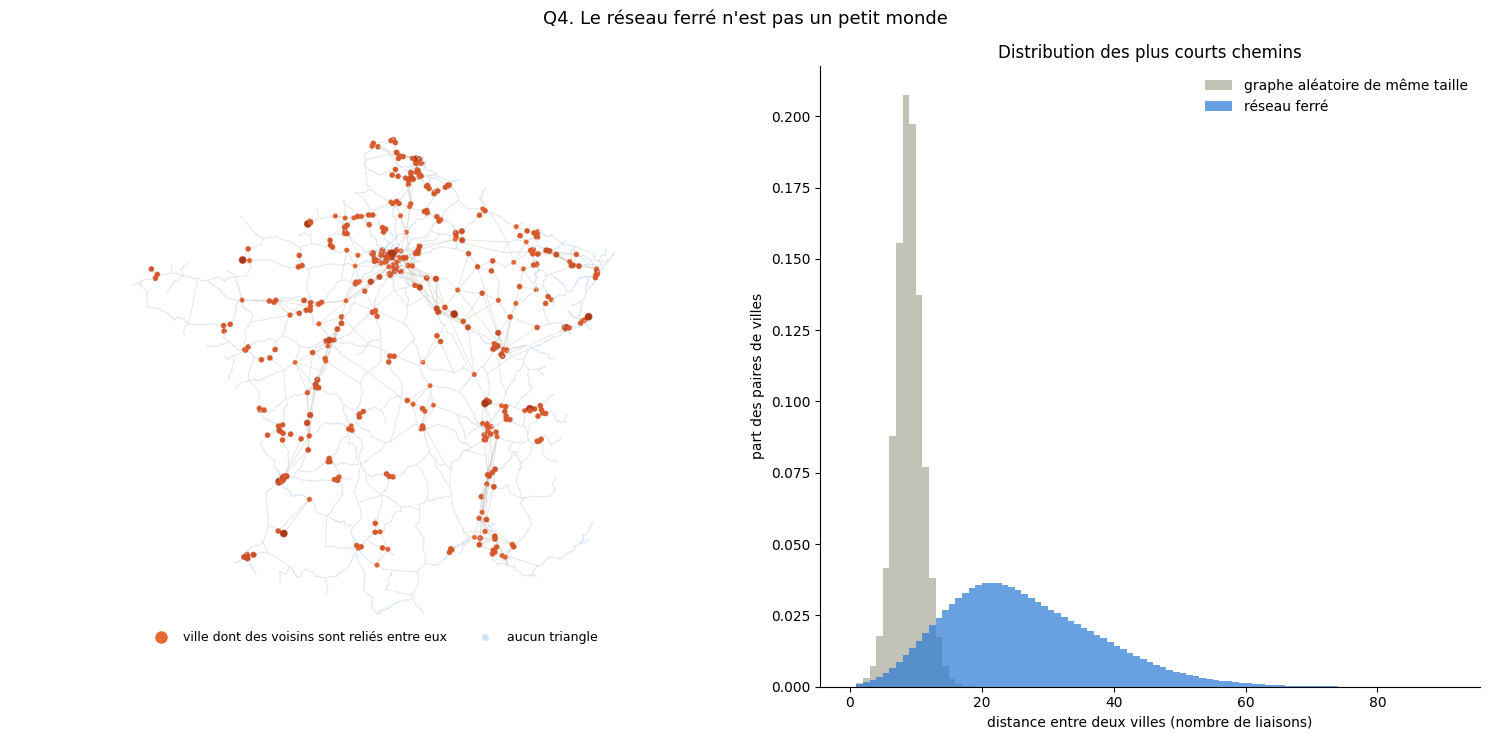

In [5]:
# Un petit monde (cours, Milgram) : plus courts chemins courts ET fort regroupement (coefficient de clustering).
# Valeurs de Cytoscape (Analyze Network, réseau des villes) comparées à 10 graphes aléatoires de même taille.
n, m = P.number_of_nodes(), P.number_of_edges()
reel = {"longueur moyenne des chemins (liaisons)": float(analyse_base["avSpl"]),
        "coefficient de regroupement": float(analyse_base["cc"])}
aleatoires = []
for graine in range(10):
    A = nx.gnm_random_graph(n, m, seed=graine)
    A = A.subgraph(max(nx.connected_components(A), key=len))
    aleatoires.append({"longueur moyenne des chemins (liaisons)": nx.average_shortest_path_length(A),
                       "coefficient de regroupement": nx.average_clustering(A)})
display(pd.DataFrame({"réseau ferré (Cytoscape)": reel, "graphe aléatoire (moyenne de 10)": pd.DataFrame(aleatoires).mean()}).round(3))

# Distribution des distances, en nombre de liaisons, entre toutes les paires de villes
def distances(H):
    return pd.Series([d for _, dist in nx.all_pairs_shortest_path_length(H) for d in dist.values() if d > 0])


d_reel, d_alea = distances(P), distances(A)

# Carte : villes dont les voisins sont reliés entre eux (colonne ClusteringCoefficient d'Analyze Network)
etiquettes([])
style("Q4", noeud=4)
p4c.set_node_color_mapping("ClusteringCoefficient", [0, 0.01, 1], [CLAIR, ORANGE, "#a8391b"], style_name="Q4")
p4c.set_node_size_mapping("ClusteringCoefficient", [0, 0.01, 1], [4, 12, 20], style_name="Q4")


def histogramme(ax):
    bornes = np.arange(0, d_reel.max() + 2)
    ax.hist(d_alea, bins=bornes, density=True, color=GRIS, label="graphe aléatoire de même taille")
    ax.hist(d_reel, bins=bornes, density=True, color=BLEU, alpha=0.7, label="réseau ferré")
    ax.set_xlabel("distance entre deux villes (nombre de liaisons)")
    ax.set_ylabel("part des paires de villes")
    ax.set_title("Distribution des plus courts chemins")
    ax.legend(frameon=False)


figure("Q4_petit_monde", "Q4. Le réseau ferré n'est pas un petit monde", graphique=histogramme,
       legende=[point(ORANGE, 9, "ville dont des voisins sont reliés entre eux"), point(CLAIR, 5, "aucun triangle")])

*Figure 4.* À gauche, les villes colorées selon leur coefficient de regroupement calculé par Cytoscape (orange : au moins deux de leurs voisins sont reliés entre eux, formant un triangle). À droite, la distribution des distances entre toutes les paires de villes, en nombre de liaisons, pour le réseau ferré (bleu) et pour un graphe aléatoire de même taille (gris).

**Réponse :** non. Un petit monde, comme les réseaux sociaux du cours (les « six degrés de séparation »), combine des chemins courts et un fort regroupement. Le réseau ferré a bien un regroupement bien plus fort qu'un graphe aléatoire (0,058 contre environ 0,001), dû aux triangles des nœuds ferroviaires et de la banlieue parisienne. Mais ses chemins sont trois fois plus longs : il faut en moyenne 26 liaisons pour aller d'une ville à une autre, contre 8,5 dans le graphe aléatoire, et jusqu'à 90. Les gares s'enchaînent le long des lignes comme les perles d'un collier, sans les raccourcis qui font un petit monde : la géographie interdit les liaisons lointaines, sauf les lignes à grande vitesse.

**Q5. Où est le centre du réseau, où est sa périphérie ?**

Ville la plus proche de tout : Juvisy-sur-Orge (375 km en moyenne) ; la plus éloignée : La Brigue (895 km)
Rayon : 746 km (centre : Montluçon) ; diamètre : 1487 km (La Brigue → Brest, 144 villes traversées)


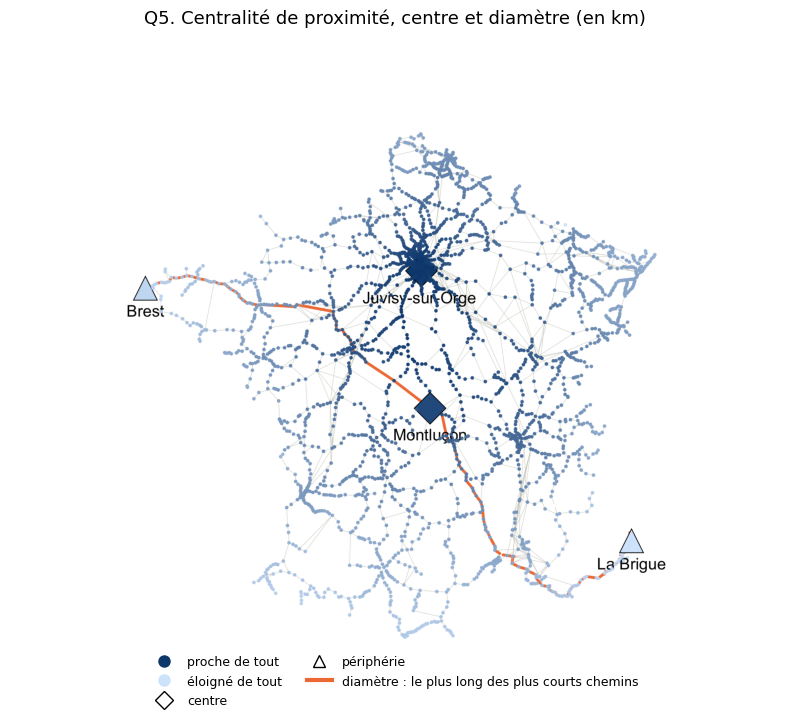

In [6]:
# Centralité de proximité : (n-1) / somme des distances en km ; excentricité : distance à la ville la plus éloignée
proximite = pd.Series(nx.closeness_centrality(P, distance=KM))
excentricite = pd.Series(nx.eccentricity(P, weight=KM))
centre = excentricite.idxmin()
bout1, bout2 = excentricite[excentricite == excentricite.max()].index[[0, -1]]
diametre = nx.shortest_path(P, bout1, bout2, weight=KM)

print(f"Ville la plus proche de tout : {villes.nom[proximite.idxmax()]} ({1 / proximite.max():.0f} km en moyenne) ; "
      f"la plus éloignée : {villes.nom[proximite.idxmin()]} ({1 / proximite.min():.0f} km)")
print(f"Rayon : {excentricite.min():.0f} km (centre : {villes.nom[centre]}) ; "
      f"diamètre : {excentricite.max():.0f} km ({villes.nom[bout1]} → {villes.nom[bout2]}, {len(diametre) - 2} villes traversées)")

colonne(proximite * 1000, "proximite")  # en 1 / 1000 km
role = pd.Series("", index=villes.index)
role[[centre, proximite.idxmax()]] = "centre"
role[[bout1, bout2]] = "périphérie"
colonne(role, "role_q5")
chemin = pd.Series("", index=liaisons.cle)
chemin[[f"{min(a, b)}~{max(a, b)}" for a, b in zip(diametre, diametre[1:])]] = "diamètre"
colonne(chemin, "chemin_q5", table="edge")
etiquettes([centre, proximite.idxmax(), bout1, bout2])

style("Q5", noeud=9)
p4c.set_node_color_mapping("proximite", [float(proximite.min() * 1000), float(proximite.max() * 1000)], [CLAIR, FONCE], style_name="Q5")
p4c.set_node_size_mapping("role_q5", ["centre", "périphérie"], [80, 60], mapping_type="d", style_name="Q5")
p4c.set_node_border_width_mapping("role_q5", ["centre", "périphérie"], [4, 4], mapping_type="d", style_name="Q5")
p4c.set_node_shape_mapping("role_q5", ["centre", "périphérie"], ["DIAMOND", "TRIANGLE"], style_name="Q5")
p4c.set_edge_color_mapping("chemin_q5", ["diamètre"], [ORANGE], mapping_type="d", style_name="Q5")
p4c.set_edge_line_width_mapping("chemin_q5", ["diamètre"], [7], mapping_type="d", style_name="Q5")
figure("Q5_centre", "Q5. Centralité de proximité, centre et diamètre (en km)",
       legende=[point(FONCE, 9, "proche de tout"), point(CLAIR, 9, "éloigné de tout"),
                Line2D([], [], color="none", marker="D", markeredgecolor="black", markerfacecolor="none", markersize=9, label="centre"),
                Line2D([], [], color="none", marker="^", markeredgecolor="black", markerfacecolor="none", markersize=9, label="périphérie"),
                trait(ORANGE, 3, "diamètre : le plus long des plus courts chemins")])

*Figure 5.* Les villes sont colorées selon leur centralité de proximité, calculée avec les distances en km (foncé : proche, en moyenne, de toutes les autres villes). Les losanges marquent les deux « centres », les triangles les deux villes de la périphérie ; le tracé orange est le diamètre du graphe.

**Réponse :** cela dépend de la mesure, comme le souligne le cours (*« l'importance dépend du contexte »*). Par la distance moyenne (proximité), le centre est Juvisy-sur-Orge, au sud de Paris, à 375 km en moyenne de toutes les autres villes : c'est là que se concentre la masse des villes. Par la distance au pire (excentricité), le centre est Montluçon, au milieu géographique du pays : aucune ville n'en est à plus de 746 km (le rayon). La proximité décroît régulièrement depuis l'Île-de-France, signature d'un réseau organisé en étoile. La périphérie oppose Brest et La Brigue (Alpes-Maritimes) : 1 487 km de voie, le plus long des plus courts chemins de France (le diamètre).

**Q6. Quels sont les points de passage obligés ?**

,ville,intermédiarité,voyageurs 2025 (millions)
75056,Paris,0.290,793.3
93066,Saint-Denis,0.163,76.1
60175,Creil,0.140,7.4
18279,Vierzon,0.139,1.7
69123,Lyon,0.133,62.9
95019,Arnouville,0.132,13.4
95268,Garges-lès-Gonesse,0.132,23.7
95280,Goussainville,0.132,8.0


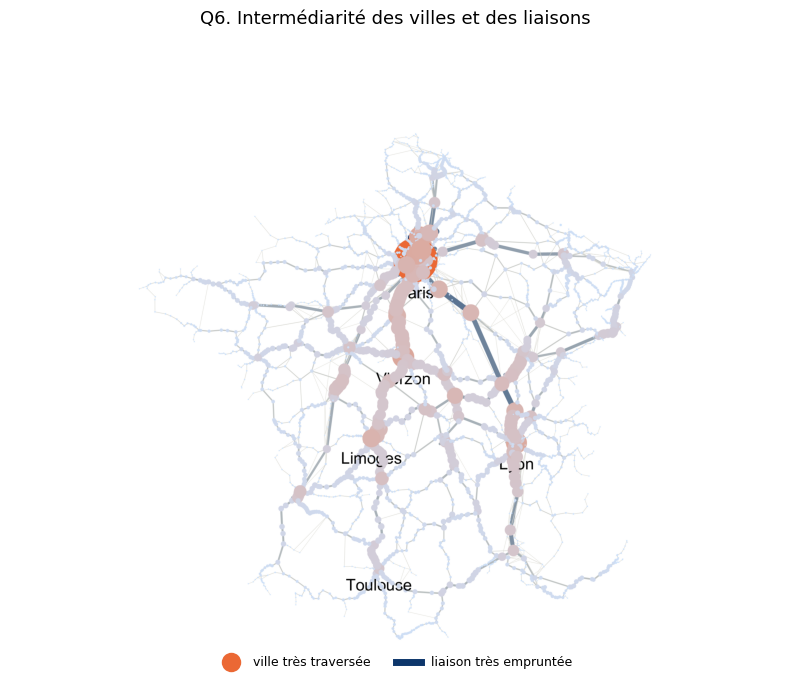

In [7]:
# Centralité d'intermédiarité (algorithme de Brandes) des villes et des liaisons, plus courts chemins en km.
# Choix justifié par la typologie des flux du cours : un voyageur, comme un colis, est transféré par le plus court chemin.
intermediarite = pd.Series(nx.betweenness_centrality(P, weight=KM))
inter_arete = nx.edge_betweenness_centrality(P, weight=KM)
liaisons["intermediarite"] = [inter_arete.get((a, b), inter_arete.get((b, a), 0)) for a, b in zip(liaisons.source, liaisons.target)]
display(pd.DataFrame({"ville": villes.nom, "intermédiarité": intermediarite.round(3),
                      "voyageurs 2025 (millions)": (villes.voyageurs_2025 / 1e6).round(1)}).dropna(subset=["intermédiarité"])
        .nlargest(8, "intermédiarité"))

colonne(intermediarite, "intermediarite")
colonne(liaisons.set_index("cle").intermediarite, "intermediarite", table="edge")
etiquettes(["75056", "18279", "69123", "60175", "87085", "31555"])  # Paris, Vierzon, Lyon, Creil, Limoges, Toulouse
style("Q6")
imax, emax = float(intermediarite.max()), float(liaisons.intermediarite.max())
p4c.set_node_size_mapping("intermediarite", [0, imax], [3, 110], style_name="Q6")
p4c.set_node_color_mapping("intermediarite", [0, imax], [CLAIR, ORANGE], style_name="Q6")
p4c.set_edge_line_width_mapping("intermediarite", [0, emax], [0.8, 22], style_name="Q6")
p4c.set_edge_color_mapping("intermediarite", [0, emax], ["#d9d8d0", FONCE], style_name="Q6")
figure("Q6_intermediarite", "Q6. Intermédiarité des villes et des liaisons",
       legende=[point(ORANGE, 14, "ville très traversée"), trait(FONCE, 5, "liaison très empruntée")])

*Figure 6.* La taille et la couleur des villes codent leur centralité d'intermédiarité, de bleu clair à orange (part des plus courts chemins, entre toutes les paires de villes, qui passent par elles) ; l'épaisseur et la teinte des liaisons codent la même mesure pour les arêtes.

**Réponse :** le principal point de passage obligé est Paris, par où passent 29 % des plus courts chemins. Viennent ensuite la banlieue nord (Saint-Denis, Creil), passage obligé vers Lille, puis Vierzon et Lyon. Vierzon, petite gare peu fréquentée, est incontournable parce que s'y croisent l'axe Paris-Toulouse et la transversale Nantes-Lyon : comme un métabolite par lequel passent de nombreuses voies, son importance tient à sa position et non à sa taille. Les liaisons les plus épaisses dessinent l'ossature du réseau : Paris-Orléans-Limoges-Toulouse et Paris-Lyon-Marseille.

**Q7. Le réseau résiste-t-il à la perte de villes ?**

318 points d'articulation (12% des villes) ; pire retrait : Carnoules, qui coupe 34 villes


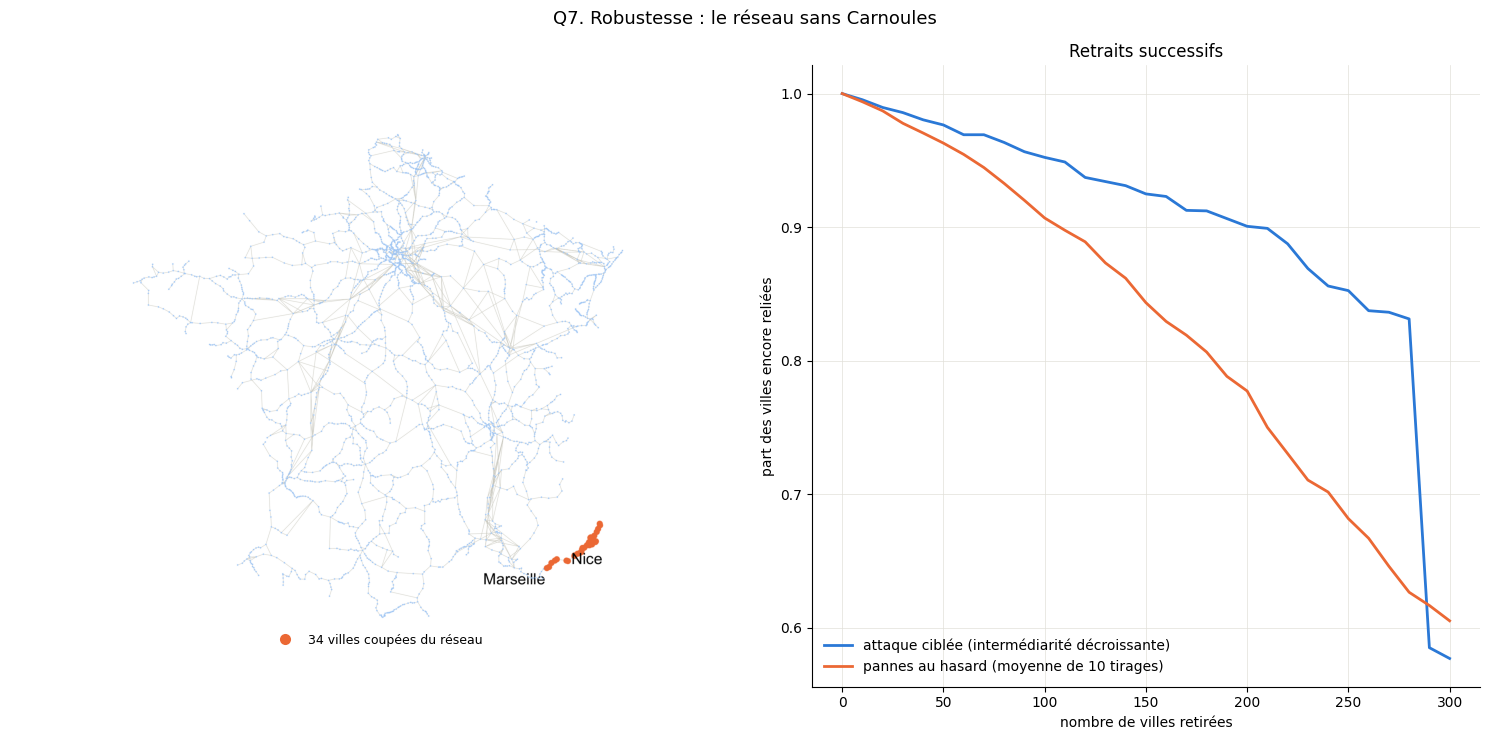

In [8]:
# Points d'articulation : villes dont le retrait coupe le réseau (l'équivalent des « points d'étranglement » du cours)
isolees = {}
for v in nx.articulation_points(P):
    H = P.copy()
    H.remove_node(v)
    isolees[v] = P.number_of_nodes() - 1 - len(max(nx.connected_components(H), key=len))
isolees = pd.Series(isolees).sort_values(ascending=False)
pire = isolees.index[0]
H = P.copy()
H.remove_node(pire)
coupees = set(P) - max(nx.connected_components(H), key=len) - {pire}
print(f"{len(isolees)} points d'articulation ({len(isolees) / len(P):.0%} des villes) ; "
      f"pire retrait : {villes.nom[pire]}, qui coupe {len(coupees)} villes")


def part_reliee(ordre, n=300, pas=10):
    """Retire les villes de `ordre` une à une ; part des villes restant dans la plus grande composante."""
    H, resultat = P.copy(), {0: 1.0}
    for i, v in enumerate(ordre[:n], start=1):
        H.remove_node(v)
        if i % pas == 0:
            resultat[i] = len(max(nx.connected_components(H), key=len)) / len(P)
    return pd.Series(resultat)


attaque = part_reliee(list(intermediarite.sort_values(ascending=False).index))  # attaque ciblée
random.seed(1)
panne = sum(part_reliee(random.sample(list(P), 300)) for _ in range(10)) / 10   # pannes au hasard

# Dans Cytoscape : copie du réseau (Clone Current Network), sélection de la ville, Edit → Delete Selected Nodes
etat = pd.Series("", index=villes.index)
etat[list(coupees)] = "coupée"
colonne(etat, "etat_q7")
etiquettes([pire, "13055", "06088"])
copie = p4c.clone_network(BASE)
p4c.select_nodes([pire], by_col="cle", preserve_current_selection=False, network=copie)
p4c.delete_selected_nodes(network=copie)
style("Q7", copie, noeud=4)
p4c.set_node_color_mapping("etat_q7", ["coupée"], [ORANGE], mapping_type="d", default_color="#9ec5f4", style_name="Q7")
p4c.set_node_size_mapping("etat_q7", ["coupée"], [16], mapping_type="d", default_size=4, style_name="Q7")


def courbe(ax):
    ax.plot(attaque, color=BLEU, lw=2, label="attaque ciblée (intermédiarité décroissante)")
    ax.plot(panne, color=ORANGE, lw=2, label="pannes au hasard (moyenne de 10 tirages)")
    ax.set_xlabel("nombre de villes retirées")
    ax.set_ylabel("part des villes encore reliées")
    ax.set_title("Retraits successifs")
    ax.grid(color="#e1e0d9", lw=0.5)
    ax.legend(frameon=False, loc="lower left")


figure("Q7_robustesse", f"Q7. Robustesse : le réseau sans {villes.nom[pire]}", reseau=copie, graphique=courbe,
       legende=[point(ORANGE, 8, f"{len(coupees)} villes coupées du réseau")])

*Figure 7.* À gauche, une copie du réseau dans Cytoscape, dont on a supprimé Carnoules (Var), le point d'articulation le plus critique ; en orange, les villes qui ne sont plus reliées au reste du réseau. À droite, la part des villes encore reliées quand on retire les villes une à une, par ordre d'intermédiarité décroissante (bleu) ou au hasard (orange).

**Réponse :** le réseau est solide au centre et fragile en périphérie. 12 % des villes sont des points d'articulation, presque toutes sur des lignes en cul-de-sac. Le pire retrait, Carnoules, est sur la seule ligne qui dessert la Côte d'Azur : il coupe 34 villes, de Toulon à Nice. À l'inverse, retirer Paris n'isole aucune ville, car la grande ceinture contourne la capitale. Le cours annonce qu'un réseau sans échelle résiste aux pannes au hasard mais pas à une attaque ciblée de ses carrefours. Ici c'est l'inverse jusqu'à environ 280 retraits : une panne au hasard tombe souvent sur une ligne en cul-de-sac, alors que les villes les plus centrales sont dans des zones maillées, où il existe toujours un itinéraire de secours.

**Q8. Quels trajets la promotion emprunte-t-elle pour venir à Rouen ?**

,train_km,vol_oiseau_km,villes_traversees,detour
Paris,133.05,115.39,23.0,1.15
Évry,153.69,136.99,32.0,1.12
Nantes,475.99,318.90,42.0,1.49
Dijon,438.00,382.26,43.0,1.15
Lyon,580.31,499.71,48.0,1.16
Toulouse,827.48,645.90,97.0,1.28
Montpellier,888.23,680.67,78.0,1.30


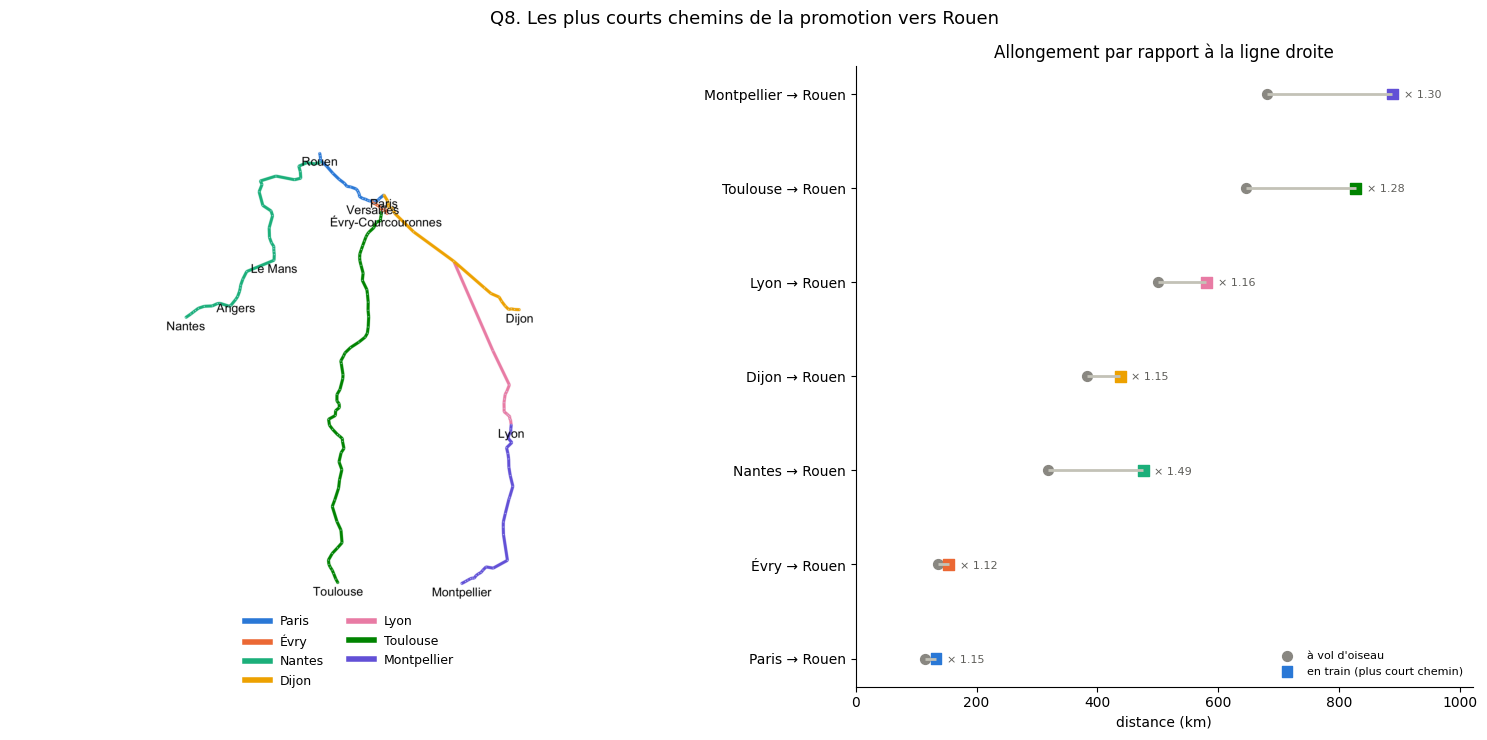

In [9]:
# Plus court chemin pondéré (algorithme de Dijkstra) sur les seules liaisons parcourues par au moins un train
# (toutes les liaisons en Île-de-France, faute d'horaires de banlieue), puis sous-réseau formé par l'union des chemins
ROUEN = "76540"
ORIGINES = {"Paris": "75056", "Évry": "91228", "Nantes": "44109", "Dijon": "21231",
            "Lyon": "69123", "Montpellier": "34172", "Toulouse": "31555"}
idf = set(villes.index[villes.region == "11"])
desservi = P.edge_subgraph([(a, b) for a, b, t in P.edges(data="nb_trains_jour") if t > 0 or (a in idf and b in idf)])

trajets = {}
for nom, origine in ORIGINES.items():
    chemin = nx.shortest_path(desservi, origine, ROUEN, weight=KM)
    trajets[nom] = {"chemin": chemin, "train_km": nx.path_weight(desservi, chemin, weight=KM),
                    "vol_oiseau_km": float(np.hypot((villes.lon[origine] - villes.lon[ROUEN]) * 76.6,  # km par degré en France
                                                     (villes.lat[origine] - villes.lat[ROUEN]) * 110.6)),
                    "villes_traversees": len(chemin) - 2}
trajets = pd.DataFrame(trajets).T.sort_values("vol_oiseau_km")
trajets["detour"] = trajets.train_km / trajets.vol_oiseau_km
display(trajets.drop(columns="chemin").astype(float).round(2))

# Colonne « trajet » sur les arêtes (une liaison partagée prend la couleur du trajet le plus court)
COULEURS = dict(zip(trajets.index, [BLEU, ORANGE, "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]))
trajet_arete = pd.Series("", index=liaisons.cle)
for nom, chemin in trajets.chemin[::-1].items():
    trajet_arete[[f"{min(a, b)}~{max(a, b)}" for a, b in zip(chemin, chemin[1:])]] = nom
colonne(trajet_arete, "trajet_rouen", table="edge")
noeuds = sorted({v for chemin in trajets.chemin for v in chemin})
etiquettes(list(ORIGINES.values()) + [ROUEN, "78646", "49007", "72181"])  # + Versailles, Angers, Le Mans

# Sous-réseau dans Cytoscape (File → New Network → From Selected Nodes, Selected Edges)
sous_reseau = p4c.create_subnetwork(nodes=noeuds, nodes_by_col="cle", edges=list(trajet_arete[trajet_arete != ""].index),
                                    edges_by_col="cle", exclude_edges=True, subnetwork_name="Trajets vers Rouen", network=BASE)
style("Q8", sous_reseau, noeud=2, arete=6, police=24)
p4c.set_edge_color_mapping("trajet_rouen", list(COULEURS), list(COULEURS.values()), mapping_type="d", style_name="Q8")


def distances(ax):
    y = np.arange(len(trajets))
    ax.hlines(y, trajets.vol_oiseau_km, trajets.train_km, color=GRIS, lw=2)
    ax.scatter(trajets.vol_oiseau_km, y, color="#898781", s=50, label="à vol d'oiseau")
    ax.scatter(trajets.train_km, y, color=[COULEURS[t] for t in trajets.index], s=60, marker="s", label="en train (plus court chemin)")
    for i, (x, r) in enumerate(zip(trajets.train_km, trajets.detour)):
        ax.annotate(f"× {r:.2f}", (x, i), xytext=(8, -3), textcoords="offset points", fontsize=8, color="#5f5e5a")
    ax.set_yticks(y, [f"{t} → Rouen" for t in trajets.index])
    ax.set_xlim(0, trajets.train_km.max() * 1.15)
    ax.set_xlabel("distance (km)")
    ax.set_title("Allongement par rapport à la ligne droite")
    ax.legend(frameon=False, loc="lower right", fontsize=8)


figure("Q8_rouen", "Q8. Les plus courts chemins de la promotion vers Rouen", reseau=sous_reseau, graphique=distances,
       legende=[trait(c, 4, t) for t, c in COULEURS.items()])

*Figure 8.* À gauche, le sous-réseau extrait dans Cytoscape : l'union des plus courts chemins (en km, sur les liaisons parcourues par des trains) des villes d'origine de la promotion jusqu'à Rouen, chaque trajet dans sa couleur. À droite, la longueur de chaque trajet comparée à la ligne droite, avec le facteur d'allongement.

**Réponse :** les sept trajets forment un arbre dont Rouen est la racine, propriété des plus courts chemins vers un même nœud. Six passent par Versailles avant de rejoindre la ligne Paris-Rouen ; seul celui de Nantes arrive par l'ouest, via Angers et Le Mans. Le train allonge les trajets de 12 à 49 % par rapport à la ligne droite ; le pire est Nantes → Rouen (× 1,49), faute de ligne directe entre la Loire et la Normandie. Comme le cours le rappelle pour les voies métaboliques, le plus court chemin reste une hypothèse « parcimonieuse » : il ignore les changements de train et les horaires, et le trajet Paris → Rouen calculé part de la rive gauche, alors que les vrais trains partent de Saint-Lazare.

**Q9. Les régions sont-elles reliées entre elles de façon équilibrée ?**

,nom,part_communes_avec_gare,part_population_avec_gare,regions_voisines
code,,,,
28,Normandie,3.93,33.2,5
53,Bretagne,9.15,34.4,2
27,Bourgogne-Franche-Comté,5.16,38.8,4
75,Nouvelle-Aquitaine,7.17,39.2,4
84,Auvergne-Rhône-Alpes,7.25,40.9,5
24,Centre-Val de Loire,8.67,42.1,6
76,Occitanie,5.58,43.1,3
52,Pays de la Loire,9.93,44.0,4
44,Grand Est,6.86,44.2,3


Applying default style...
Applying preferred layout


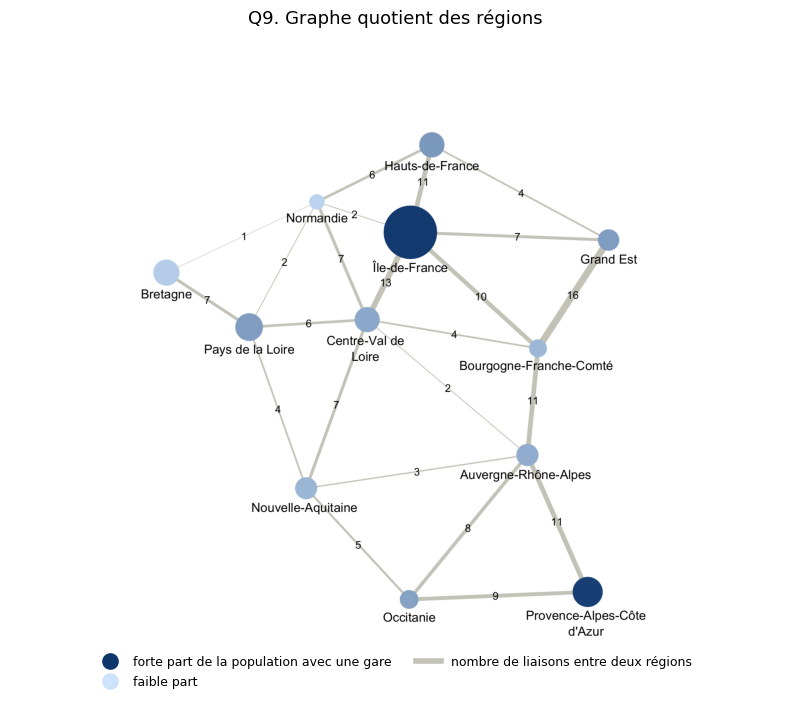

In [10]:
# Graphe quotient : toutes les villes d'une région forment un seul nœud ; une arête entre deux régions
# porte le nombre de liaisons qui les relient (comme on regroupe les métabolites par voie métabolique)
regions = pd.read_csv(DONNEES / "regions.csv", dtype={"code": str}).set_index("code")
blocs = [set(groupe.index) for _, groupe in villes.loc[list(P)].groupby("region")]
R = nx.quotient_graph(P, blocs, relabel=False)
R = nx.relabel_nodes(R, {bloc: villes.region[next(iter(bloc))] for bloc in R})
display(regions.loc[list(R), ["nom", "part_communes_avec_gare", "part_population_avec_gare"]]
        .assign(regions_voisines=[R.degree(r) for r in R]).sort_values("part_population_avec_gare"))

noeuds = regions.loc[list(R)].reset_index().rename(columns={"code": "id"})
aretes = pd.DataFrame([(a, b, w) for a, b, w in R.edges(data="weight")], columns=["source", "target", "liaisons"])
lon = villes.loc[list(P)].groupby("region").lon.mean()[list(R)]
lat = villes.loc[list(P)].groupby("region").lat.mean()[list(R)]
regions_cy = nouveau_reseau(noeuds, aretes, "Graphe des régions", lon * 100, -lat * 145)  # chaque région au barycentre de ses villes
style("Q9", regions_cy, arete=2, etiquette="nom", police=26)
p4c.set_edge_font_size_default(22, style_name="Q9")
p4c.set_node_size_mapping("part_communes_avec_gare", [0, float(regions.part_communes_avec_gare.max())], [15, 110], style_name="Q9")
p4c.set_node_color_mapping("part_population_avec_gare", [30, 65], [CLAIR, FONCE], style_name="Q9")
p4c.set_edge_line_width_mapping("liaisons", [1, float(aretes.liaisons.max())], [1, 14], style_name="Q9")
p4c.set_edge_label_mapping("liaisons", style_name="Q9")
figure("Q9_regions", "Q9. Graphe quotient des régions", reseau=regions_cy,
       legende=[point(FONCE, 12, "forte part de la population avec une gare"), point(CLAIR, 12, "faible part"),
                trait(GRIS, 4, "nombre de liaisons entre deux régions")])

*Figure 9.* Le graphe quotient des régions, construit avec NetworkX puis dessiné dans Cytoscape : un nœud par région, placé au barycentre de ses villes. La taille code la part des communes qui ont une gare, la couleur la part de la population qui habite une commune avec gare ; le nombre sur chaque arête est celui des liaisons entre les deux régions.

**Réponse :** non. L'Île-de-France et Provence-Alpes-Côte d'Azur sont les mieux couvertes, avec environ 63 % de la population dans une commune avec gare, contre un tiers seulement en Normandie et en Bretagne. Les liaisons entre régions sont aussi très inégales : la Normandie, région de Rouen, n'est reliée à l'Île-de-France que par 2 liaisons, un goulot d'étranglement pour les trajets de la promotion (Q8) ; la Bretagne n'est reliée qu'aux Pays de la Loire et à la Normandie, alors que le Grand Est et la Bourgogne-Franche-Comté partagent 16 liaisons. Regrouper les nœuds simplifie le graphe et fait apparaître ces déséquilibres, invisibles à l'échelle des 2 597 villes.

**Q10. Compter des liaisons ou des kilomètres change-t-il les réponses ?**

,écart maximal Cytoscape / NetworkX,"en tête, en liaisons (Cytoscape)","en tête, en km (NetworkX)",corrélation de rang km / liaisons
ClosenessCentrality,1.387779e-17,Montereau-Fault-Yonne,Juvisy-sur-Orge,0.75
BetweennessCentrality,2.275957e-15,Commune Nouvelle D'Arrou,Paris,0.33
Eccentricity,0.000000e+00,Colombier-Saugnieu,Montluçon,0.55


Le plus de gares : Err → Brest, 90 liaisons, 1767 km ; le plus long en km : La Brigue → Brest, 145 liaisons, 1487 km


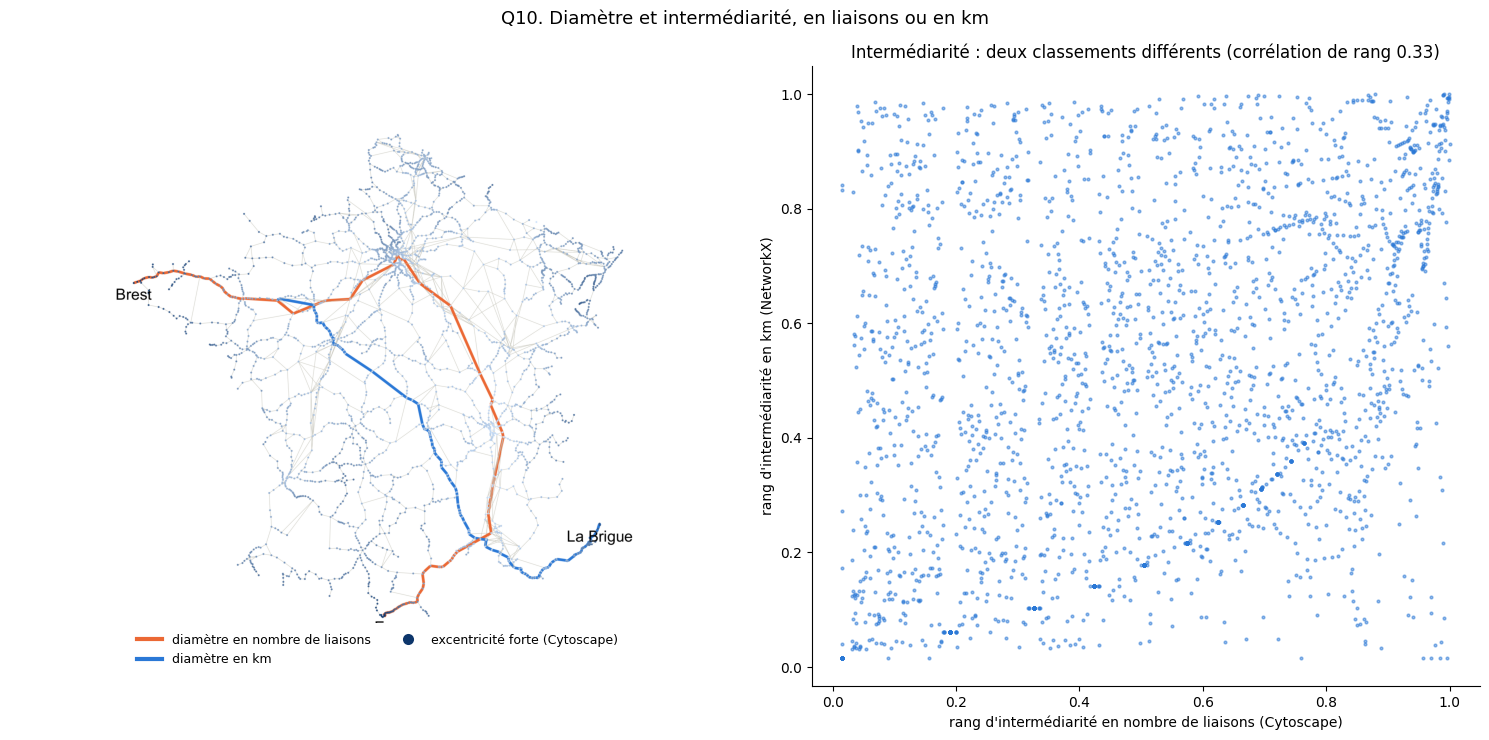

In [11]:
# Analyze Network (lancé en Q3) ignore les poids : il compte des liaisons. On compare ses colonnes
# à NetworkX sans poids (doivent être identiques), puis aux mesures en km de ce rapport.
cy = p4c.get_table_columns("node", network=BASE).set_index("cle").loc[list(P)]
sans_poids = pd.DataFrame({"ClosenessCentrality": nx.closeness_centrality(P),
                           "BetweennessCentrality": nx.betweenness_centrality(P),
                           "Eccentricity": nx.eccentricity(P)})
en_km = pd.DataFrame({"ClosenessCentrality": proximite, "BetweennessCentrality": intermediarite, "Eccentricity": excentricite})
controle = pd.DataFrame({
    "écart maximal Cytoscape / NetworkX": (cy[sans_poids.columns].astype(float) - sans_poids).abs().max(),
    "en tête, en liaisons (Cytoscape)": [villes.nom[cy[c].astype(float).idxmin() if c == "Eccentricity" else cy[c].astype(float).idxmax()] for c in sans_poids],
    "en tête, en km (NetworkX)": [villes.nom[en_km[c].idxmin() if c == "Eccentricity" else en_km[c].idxmax()] for c in sans_poids],
    "corrélation de rang km / liaisons": [round(en_km[c].corr(sans_poids[c], method="spearman"), 2) for c in sans_poids]})
display(controle)

# Diamètre en nombre de liaisons : le trajet qui traverse obligatoirement le plus de gares
depart = sans_poids.Eccentricity.idxmax()
liaisons_depuis = nx.single_source_shortest_path_length(P, depart)
arrivee = max(liaisons_depuis, key=liaisons_depuis.get)
plus_d_arrets = nx.shortest_path(P, depart, arrivee)
print(f"Le plus de gares : {villes.nom[depart]} → {villes.nom[arrivee]}, {len(plus_d_arrets) - 1} liaisons, "
      f"{nx.path_weight(P, plus_d_arrets, KM):.0f} km ; le plus long en km : {villes.nom[bout1]} → {villes.nom[bout2]}, "
      f"{len(diametre) - 1} liaisons, {excentricite.max():.0f} km")

chemins = pd.Series("", index=liaisons.cle)
chemins[[f"{min(a, b)}~{max(a, b)}" for a, b in zip(diametre, diametre[1:])]] = "km"
chemins[[f"{min(a, b)}~{max(a, b)}" for a, b in zip(plus_d_arrets, plus_d_arrets[1:])]] = "liaisons"
colonne(chemins, "diametre_q10", table="edge")
etiquettes([depart, arrivee, bout1])
style("Q10", noeud=5)
p4c.set_node_color_mapping("Eccentricity", [float(cy.Eccentricity.min()), float(cy.Eccentricity.max())], [CLAIR, FONCE], style_name="Q10")
p4c.set_edge_color_mapping("diametre_q10", ["liaisons", "km"], [ORANGE, BLEU], mapping_type="d", style_name="Q10")
p4c.set_edge_line_width_mapping("diametre_q10", ["liaisons", "km"], [7, 7], mapping_type="d", style_name="Q10")


def rangs(ax):
    ax.scatter(sans_poids.BetweennessCentrality.rank(pct=True), en_km.BetweennessCentrality.rank(pct=True), s=4, color=BLEU, alpha=0.5)
    ax.set_xlabel("rang d'intermédiarité en nombre de liaisons (Cytoscape)")
    ax.set_ylabel("rang d'intermédiarité en km (NetworkX)")
    rho = controle.loc["BetweennessCentrality", "corrélation de rang km / liaisons"]
    ax.set_title(f"Intermédiarité : deux classements différents (corrélation de rang {rho})")


figure("Q10_km_ou_liaisons", "Q10. Diamètre et intermédiarité, en liaisons ou en km", graphique=rangs,
       legende=[trait(ORANGE, 3, "diamètre en nombre de liaisons"), trait(BLEU, 3, "diamètre en km"),
                point(FONCE, 8, "excentricité forte (Cytoscape)")])

*Figure 10.* À gauche, les villes colorées selon l'excentricité calculée par Cytoscape (en nombre de liaisons), avec les deux diamètres : en orange le trajet qui traverse le plus de gares, en bleu le trajet le plus long en km. À droite, chaque point est une ville : son rang d'intermédiarité en nombre de liaisons (Cytoscape) contre son rang en km (NetworkX).

**Réponse :** oui, et beaucoup. Sans poids, Cytoscape et NetworkX donnent les mêmes valeurs à l'arrondi près : les deux outils sont fiables. Mais *Analyze Network* ignore les km, et compter des liaisons change les réponses. Le trajet qui traverse le plus de gares relie Err (Pyrénées-Orientales) à Brest, par Paris et les lignes à grande vitesse, où les gares sont rares ; le plus long en km relie La Brigue à Brest par le Massif central. Le centre passe de Montluçon à Colombier-Saugnieu, et les deux classements d'intermédiarité ne se ressemblent presque plus. Comme le dit le cours, *« faut-il considérer tous les nœuds et toutes les arêtes comme identiques ? »* : ici, non. C'est pourquoi les mesures en km sont calculées dans NetworkX puis seulement affichées dans Cytoscape.

## Conclusion

Le réseau ferré français est une étoile centrée sur Paris (Q1, Q2, Q5, Q6). Ce n'est ni un réseau sans échelle, faute de carrefours géants (Q3), ni un petit monde, faute de raccourcis (Q4) : la géographie l'en empêche. Il est solide en son centre maillé et fragile en périphérie, sur les lignes en cul-de-sac (Q7). Les méthodes du cours s'y appliquent bien, à condition de choisir la mesure adaptée à la question et de bien définir les poids (Q10). Les limites tiennent aux données : distances en km et non en temps, changements de train ignorés, trains de banlieue absents des horaires, et un seul jour observé.